INFO - Loaded point cloud from ./KITTI-Sequence/000000/000000_points.obj.
INFO - Loaded point cloud from ./KITTI-Sequence/000001/000001_points.obj.
INFO - Loaded point cloud from ./KITTI-Sequence/000002/000002_points.obj.
INFO - Loaded point cloud from ./KITTI-Sequence/000003/000003_points.obj.
INFO - Loaded point cloud from ./KITTI-Sequence/000004/000004_points.obj.
INFO - Loaded point cloud from ./KITTI-Sequence/000005/000005_points.obj.
INFO - Loaded point cloud from ./KITTI-Sequence/000006/000006_points.obj.
INFO - Loaded point cloud from ./KITTI-Sequence/000007/000007_points.obj.
INFO - Loaded point cloud from ./KITTI-Sequence/000008/000008_points.obj.
INFO - Loaded point cloud from ./KITTI-Sequence/000009/000009_points.obj.
INFO - Loaded point cloud from ./KITTI-Sequence/000010/000010_points.obj.
INFO - Loaded point cloud from ./KITTI-Sequence/000011/000011_points.obj.
INFO - Loaded point cloud from ./KITTI-Sequence/000012/000012_points.obj.
INFO - Loaded point cloud from ./KITTI

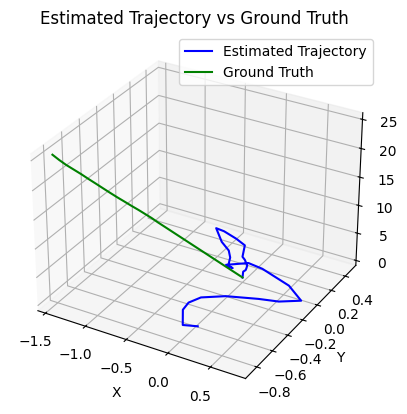

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.spatial import KDTree
import trimesh
import logging
from typing import List, Tuple

# Set up logging
logging.basicConfig(level=logging.INFO,
                    format='%(levelname)s - %(message)s')


class ICPConfig:
    MAX_ITERATIONS: int = 1
    TOLERANCE: float = 1e-5


def icp(A: np.ndarray, B: np.ndarray, config: ICPConfig) -> Tuple[np.ndarray, np.ndarray]:
    """
    Perform the Iterative Closest Point (ICP) algorithm to estimate the transformation
    between two point clouds A and B.

    Args:
        A (np.ndarray): Source point cloud.
        B (np.ndarray): Target point cloud.
        config (ICPConfig): Configuration object containing max iterations and tolerance.

    Returns:
        Tuple[np.ndarray, np.ndarray]: Estimated rotation (R) and translation (t).
    """
    # Compute centroids
    centroid_A = np.mean(A, axis=0)
    centroid_B = np.mean(B, axis=0)

    A_centered = A - centroid_A
    B_centered = B - centroid_B

    # Initialize rotation matrix and translation vector
    R = np.eye(3)
    t = np.zeros(3)

    # Build KD-tree for fast nearest neighbor search
    tree = KDTree(B_centered)

    for i in range(config.MAX_ITERATIONS):
        # Find closest points
        _, indices = tree.query(A_centered)
        closest_B = B_centered[indices]

        # Estimate the transformation
        H = A_centered.T @ closest_B
        U, S, Vt = np.linalg.svd(H)
        R_new = Vt.T @ U.T

        if np.linalg.det(R_new) < 0:
            Vt[-1, :] *= -1
            R_new = Vt.T @ U.T

        # Estimate the translation vector
        t_new = centroid_B - R_new @ centroid_A

        # Check for convergence
        if np.linalg.norm(R_new - R) < config.TOLERANCE and np.linalg.norm(t_new - t) < config.TOLERANCE:
            logging.info(f'Converged after {i+1} iterations.')
            break

        R, t = R_new, t_new

    return R, t


def load_point_clouds(scan_ids: List[int]) -> List[np.ndarray]:
    """
    Load point clouds from the KITTI dataset.

    Args:
        scan_ids (List[int]): List of scan IDs to load.

    Returns:
        List[np.ndarray]: List of loaded point clouds.
    """
    clouds = []
    for scan_id in scan_ids:
        filename = f"./KITTI-Sequence/{scan_id:06d}/{scan_id:06d}_points.obj"
        try:
            cloud = trimesh.load(filename).vertices
            clouds.append(cloud)
            logging.info(f'Loaded point cloud from {filename}.')
        except Exception as e:
            logging.error(f'Error loading {filename}: {e}')
    return clouds


def plot_trajectory(trajectory: np.ndarray, ground_truth: np.ndarray = None) -> None:
    """
    Plot the estimated trajectory and ground truth.

    Args:
        trajectory (np.ndarray): Estimated trajectory points.
        ground_truth (np.ndarray, optional): Ground truth points to plot.
    """
    fig = plt.figure()
    ax = fig.add_subplot(111, projection='3d')
    ax.plot(trajectory[:, 0], trajectory[:, 1], trajectory[:,
            2], label='Estimated Trajectory', color='b')

    if ground_truth is not None:
        ax.plot(ground_truth[:, 0], ground_truth[:, 1],
                ground_truth[:, 2], label='Ground Truth', color='g')

    ax.set_xlabel('X')
    ax.set_ylabel('Y')
    ax.set_zlabel('Z')
    ax.legend()
    plt.title('Estimated Trajectory vs Ground Truth')
    plt.show()


def main() -> None:
    # Load ground truth trajectory
    ground_truth = np.load('ground_truth.npy')
    initial_pose = ground_truth[0]
    trajectory = [initial_pose[:3, 3]]

    # Load point clouds
    scan_ids = range(30)
    point_clouds = load_point_clouds(scan_ids)

    # Accumulated transformation
    T_accumulated = np.eye(4)

    # Process point clouds
    config = ICPConfig()

    for i in range(len(point_clouds) - 1):
        logging.info(f'Processing point clouds {i} and {i + 1}')

        A = point_clouds[i]
        B = point_clouds[i + 1]

        # Estimate transformation
        R, t = icp(A, B, config)

        # Update transformation matrix
        T_icp = np.eye(4)
        T_icp[:3, :3] = R
        T_icp[:3, 3] = t
        T_accumulated = T_accumulated @ T_icp

        # Update trajectory
        trajectory.append(T_accumulated[:3, 3])

    trajectory = np.array(trajectory)

    # Plot trajectory and ground truth
    plot_trajectory(trajectory, ground_truth[:, :3, 3])


if __name__ == '__main__':
    main()
